In [4]:
# Import library dasar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Import library scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve,
    precision_score, recall_score, f1_score
)

# Setting tampilan
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

print("Semua library berhasil diimport!")

Semua library berhasil diimport!


In [5]:
from google.colab import files
uploaded = files.upload()

Saving manufacturing_defect_dataset.csv to manufacturing_defect_dataset (1).csv


In [6]:
# Load dataset
df = pd.read_csv('manufacturing_defect_dataset.csv')

# Tampilkan informasi awal
print("Ukuran dataset:", df.shape)
print("\n5 Baris Pertama:")
df.head()

Ukuran dataset: (3240, 17)

5 Baris Pertama:


,ProductionVolume,ProductionCost,SupplierQuality,DeliveryDelay,DefectRate,QualityScore,MaintenanceHours,DowntimePercentage,InventoryTurnover,StockoutRate,WorkerProductivity,SafetyIncidents,EnergyConsumption,EnergyEfficiency,AdditiveProcessTime,AdditiveMaterialCost,DefectStatus
0,202,13175.403783,86.648534,1,3.121492,63.463494,9,0.052343,8.630515,0.081322,85.042379,0,2419.616785,0.468947,5.551639,236.439301,1
1,535,19770.046093,86.310664,4,0.819531,83.697818,20,4.908328,9.296598,0.038486,99.657443,7,3915.566713,0.119485,9.080754,353.957631,1
2,960,19060.820997,82.132472,0,4.514504,90.350550,1,2.464923,5.097486,0.002887,92.819264,2,3392.385362,0.496392,6.562827,396.189402,1
3,370,5647.606037,87.335966,5,0.638524,67.628690,8,4.692476,3.577616,0.055331,96.887013,8,4652.400275,0.183125,8.097496,164.135870,1
4,206,7472.222236,81.989893,3,3.867784,82.728334,9,2.746726,6.851709,0.068047,88.315554,7,1581.630332,0.263507,6.406154,365.708964,1


In [7]:
# Informasi tipe data dan missing value
print("Informasi Dataset:")
df.info()

# Statistik deskriptif
print("\nStatistik Deskriptif:")
df.describe()

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3240 entries, 0 to 3239
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ProductionVolume      3240 non-null   int64  
 1   ProductionCost        3240 non-null   float64
 2   SupplierQuality       3240 non-null   float64
 3   DeliveryDelay         3240 non-null   int64  
 4   DefectRate            3240 non-null   float64
 5   QualityScore          3240 non-null   float64
 6   MaintenanceHours      3240 non-null   int64  
 7   DowntimePercentage    3240 non-null   float64
 8   InventoryTurnover     3240 non-null   float64
 9   StockoutRate          3240 non-null   float64
 10  WorkerProductivity    3240 non-null   float64
 11  SafetyIncidents       3240 non-null   int64  
 12  EnergyConsumption     3240 non-null   float64
 13  EnergyEfficiency      3240 non-null   float64
 14  AdditiveProcessTime   3240 non-null   float64
 15  Ad

,ProductionVolume,ProductionCost,SupplierQuality,DeliveryDelay,DefectRate,QualityScore,MaintenanceHours,DowntimePercentage,InventoryTurnover,StockoutRate,WorkerProductivity,SafetyIncidents,EnergyConsumption,EnergyEfficiency,AdditiveProcessTime,AdditiveMaterialCost,DefectStatus
count,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000,3240.000000
mean,548.523148,12423.018476,89.833290,2.558951,2.749116,80.134272,11.476543,2.501373,6.019662,0.050878,90.040115,4.591667,2988.494453,0.299776,5.472098,299.515479,0.840432
std,262.402073,4308.051904,5.759143,1.705804,1.310154,11.611750,6.872684,1.443684,2.329791,0.028797,5.723600,2.896313,1153.420820,0.116400,2.598212,116.379905,0.366261
min,100.000000,5000.174521,80.004820,0.000000,0.500710,60.010098,0.000000,0.001665,2.001611,0.000002,80.004960,0.000000,1000.720156,0.100238,1.000151,100.211137,0.000000
25%,322.000000,8728.829280,84.869219,1.000000,1.598033,70.103420,5.750000,1.264597,3.983249,0.026200,85.180203,2.000000,1988.140273,0.200502,3.228507,194.922058,1.000000
50%,549.000000,12405.204656,89.704861,3.000000,2.708775,80.265312,12.000000,2.465151,6.022389,0.051837,90.125743,5.000000,2996.822301,0.297470,5.437134,299.728918,1.000000
75%,775.250000,16124.462428,94.789936,4.000000,3.904533,90.353822,17.000000,3.774861,8.050222,0.075473,95.050838,7.000000,3984.788299,0.402659,7.741006,403.178283,1.000000
max,999.000000,19993.365549,99.989214,5.000000,4.998529,99.996993,23.000000,4.997591,9.998577,0.099997,99.996786,9.000000,4997.074741,0.499500,9.999749,499.982782,1.000000


In [8]:
# Cek missing value
print("Jumlah Missing Value per Kolom:")
missing = df.isnull().sum()
print(missing[missing > 0] if any(missing > 0) else "Tidak ada missing value!")

# Cek duplikat
print(f"\nJumlah Data Duplikat: {df.duplicated().sum()}")

Jumlah Missing Value per Kolom:
Tidak ada missing value!

Jumlah Data Duplikat: 0


Distribusi Target (DefectStatus):
DefectStatus
1    2723
0     517
Name: count, dtype: int64

Persentase:
DefectStatus
1    84.04321
0    15.95679
Name: proportion, dtype: float64


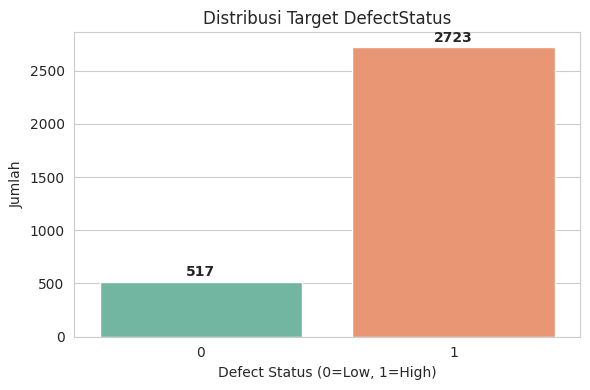

In [9]:
# Distribusi target
print("Distribusi Target (DefectStatus):")
print(df['DefectStatus'].value_counts())
print(f"\nPersentase:")
print(df['DefectStatus'].value_counts(normalize=True) * 100)

# Visualisasi
plt.figure(figsize=(6, 4))
sns.countplot(x='DefectStatus', data=df, palette='Set2')
plt.title('Distribusi Target DefectStatus')
plt.xlabel('Defect Status (0=Low, 1=High)')
plt.ylabel('Jumlah')
for i, v in enumerate(df['DefectStatus'].value_counts().sort_index()):
    plt.text(i, v + 50, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

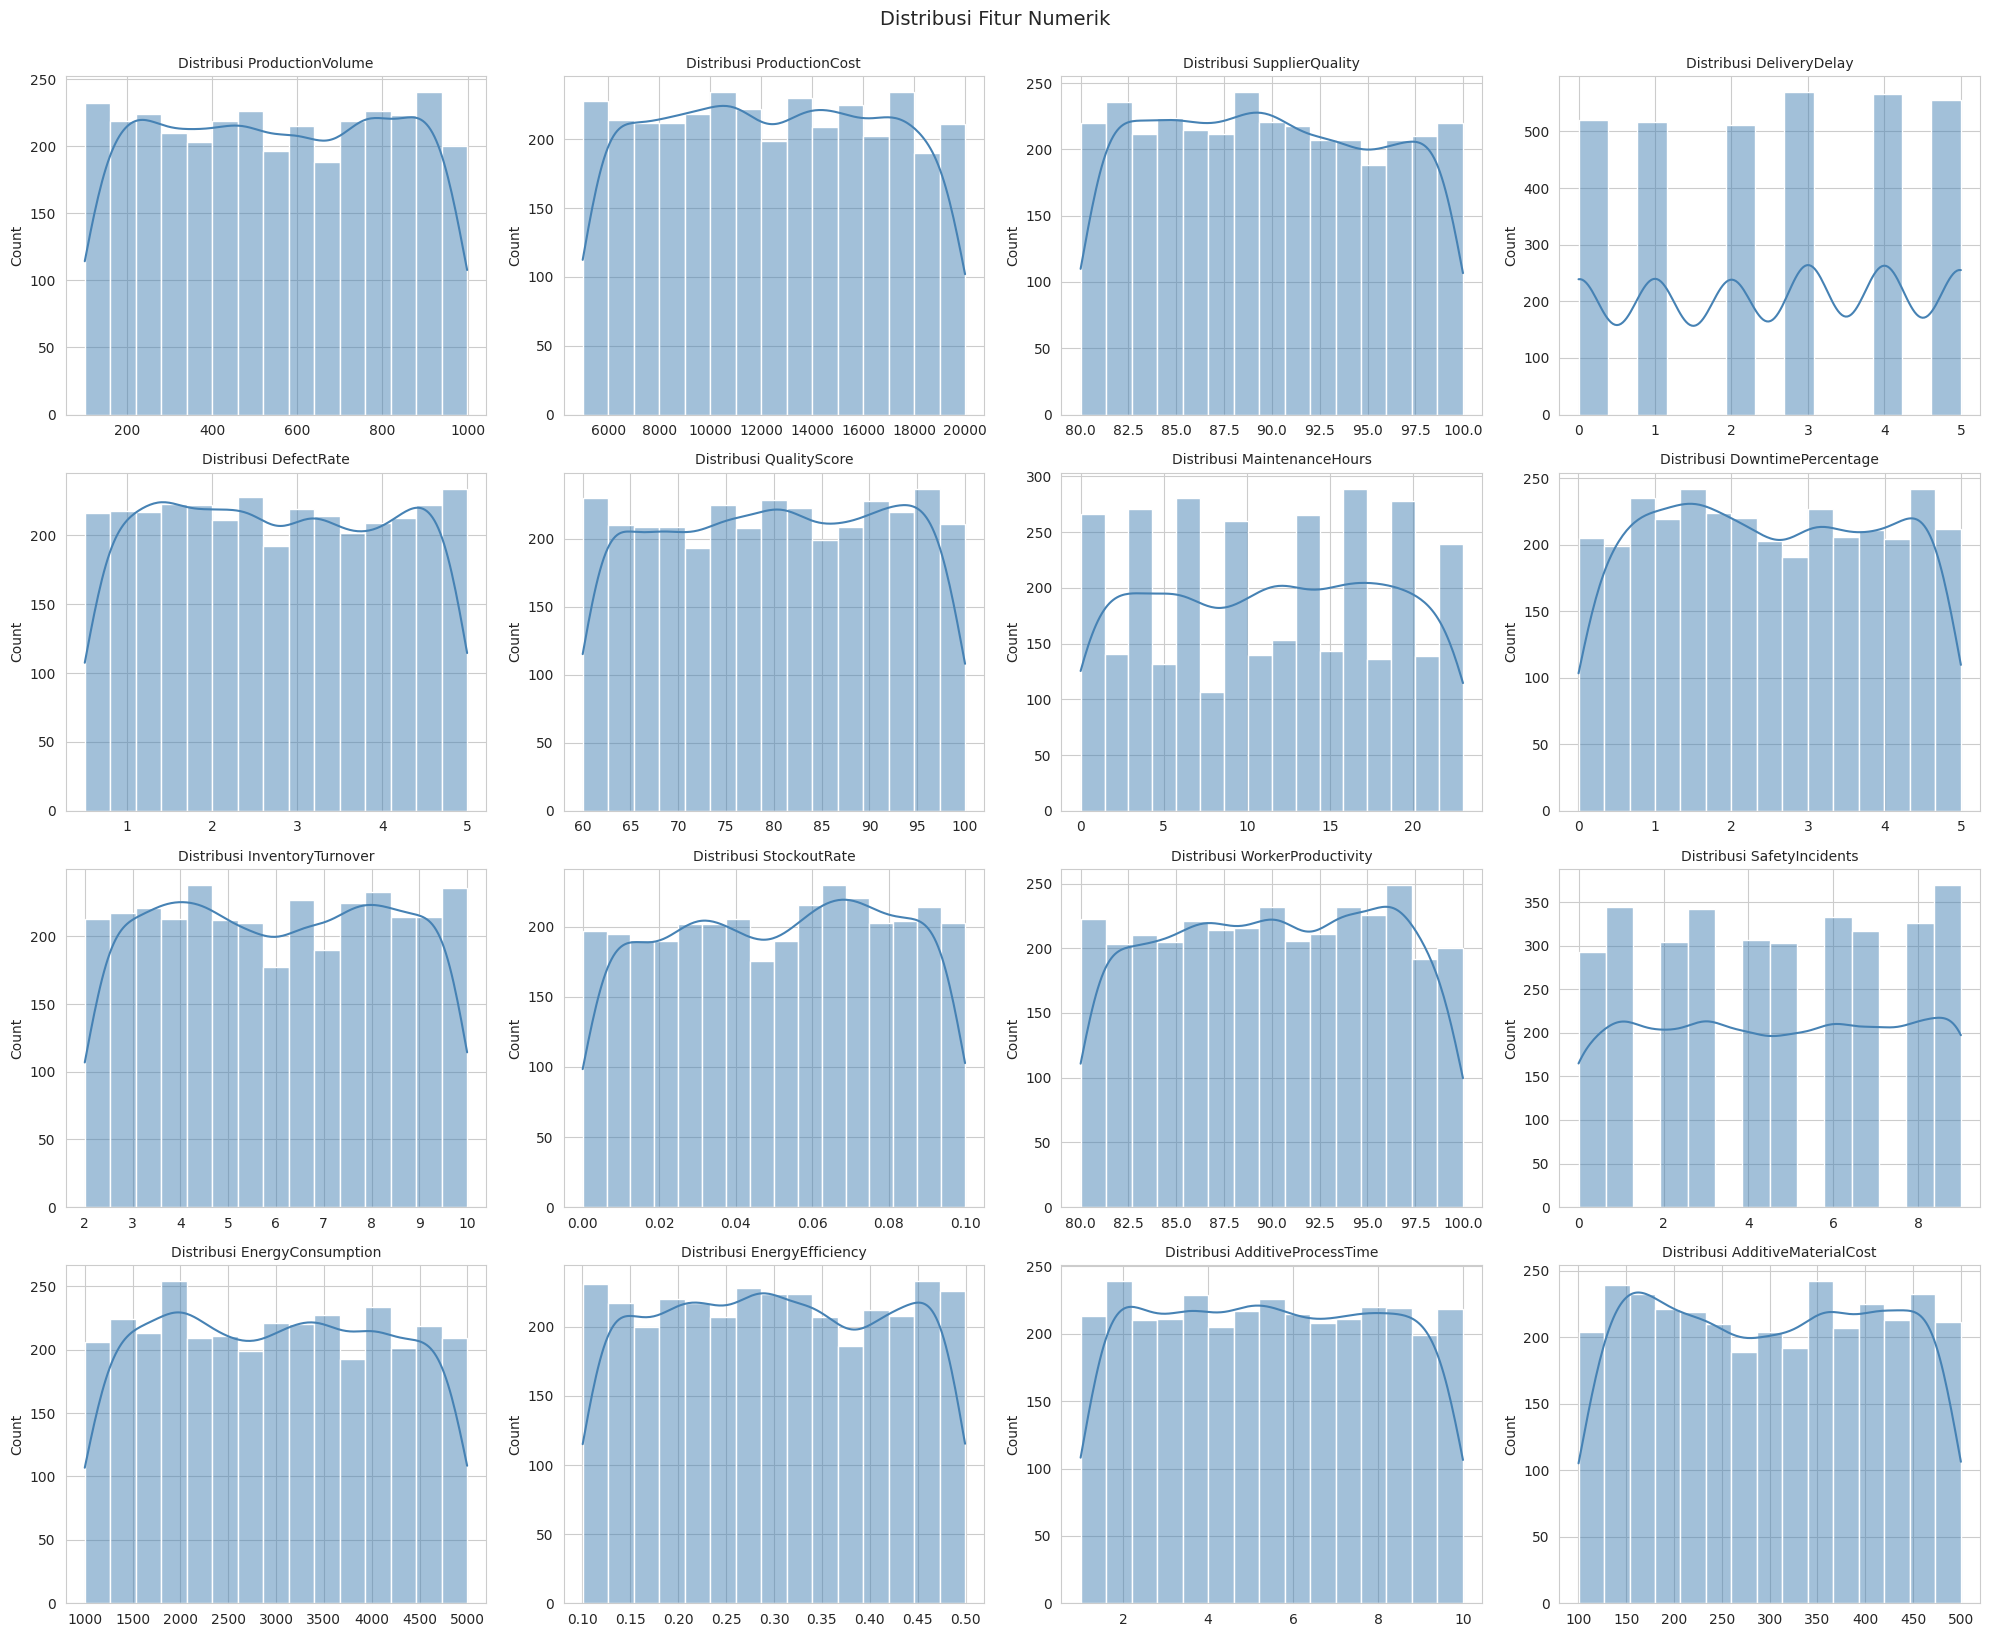

In [10]:
# Pilih fitur numerik (semua kecuali target)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols.remove('DefectStatus')

# Histogram distribusi
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribusi {col}', fontsize=10)
    axes[i].set_xlabel('')

# Hapus subplot kosong
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.suptitle('Distribusi Fitur Numerik', fontsize=14, y=1.02)
plt.show()

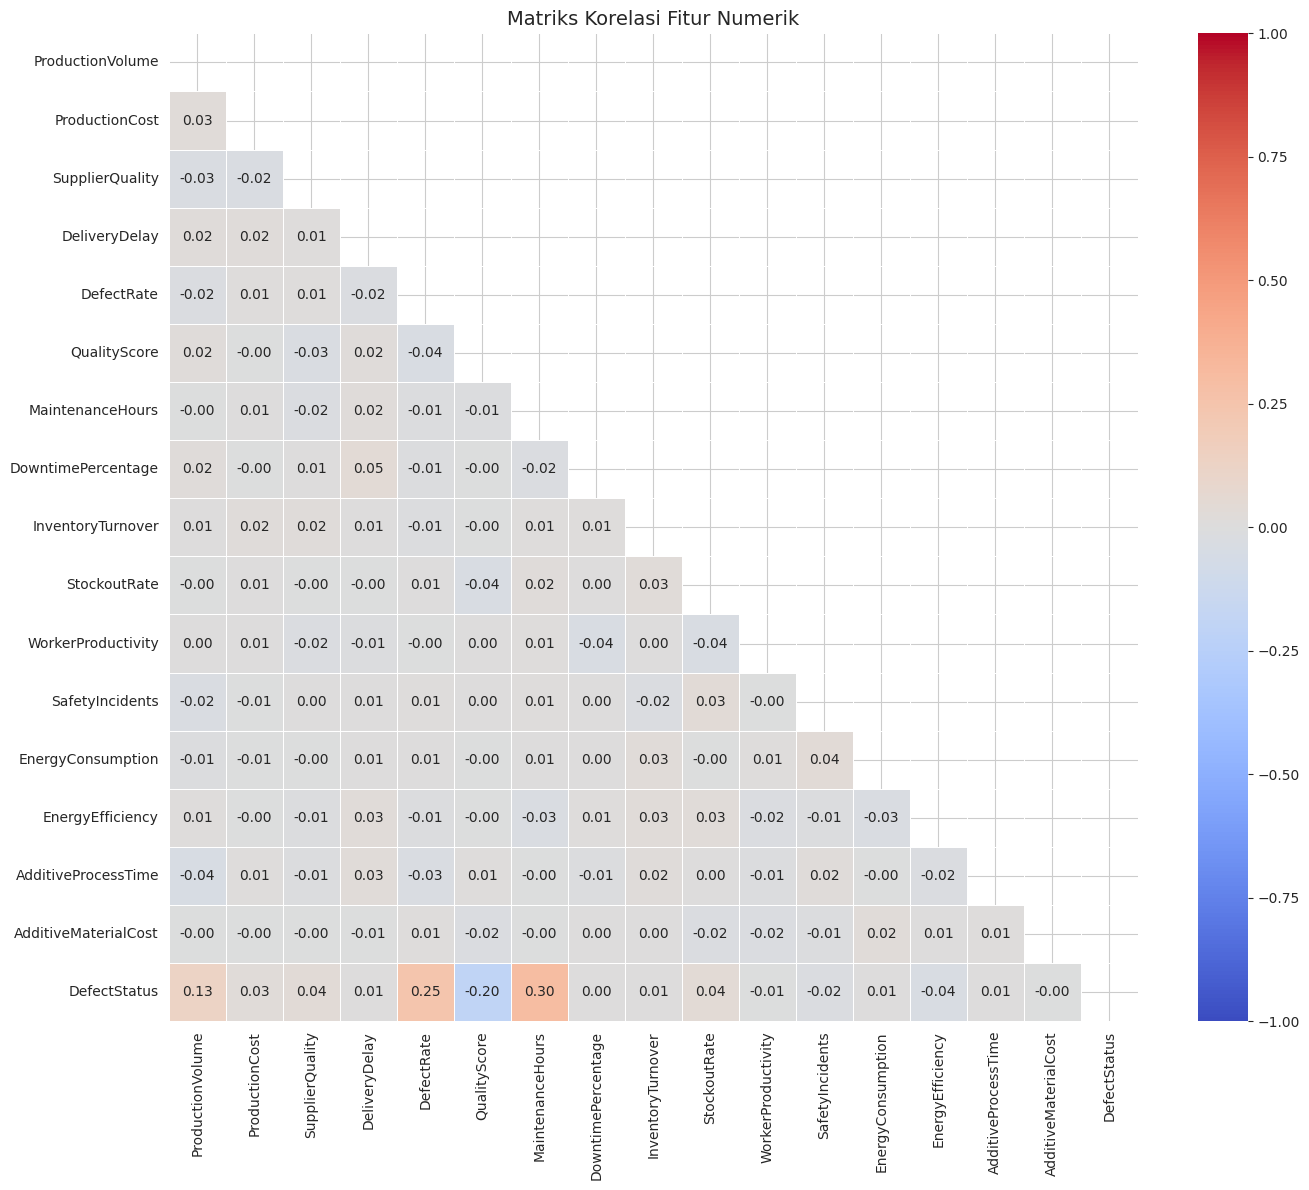

In [11]:
# Heatmap korelasi fitur numerik
plt.figure(figsize=(14, 12))
correlation = df[numeric_cols + ['DefectStatus']].corr()
mask = np.triu(np.ones_like(correlation, dtype=bool))
sns.heatmap(correlation, mask=mask, annot=True, cmap='coolwarm',
            fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriks Korelasi Fitur Numerik', fontsize=14)
plt.tight_layout()
plt.show()

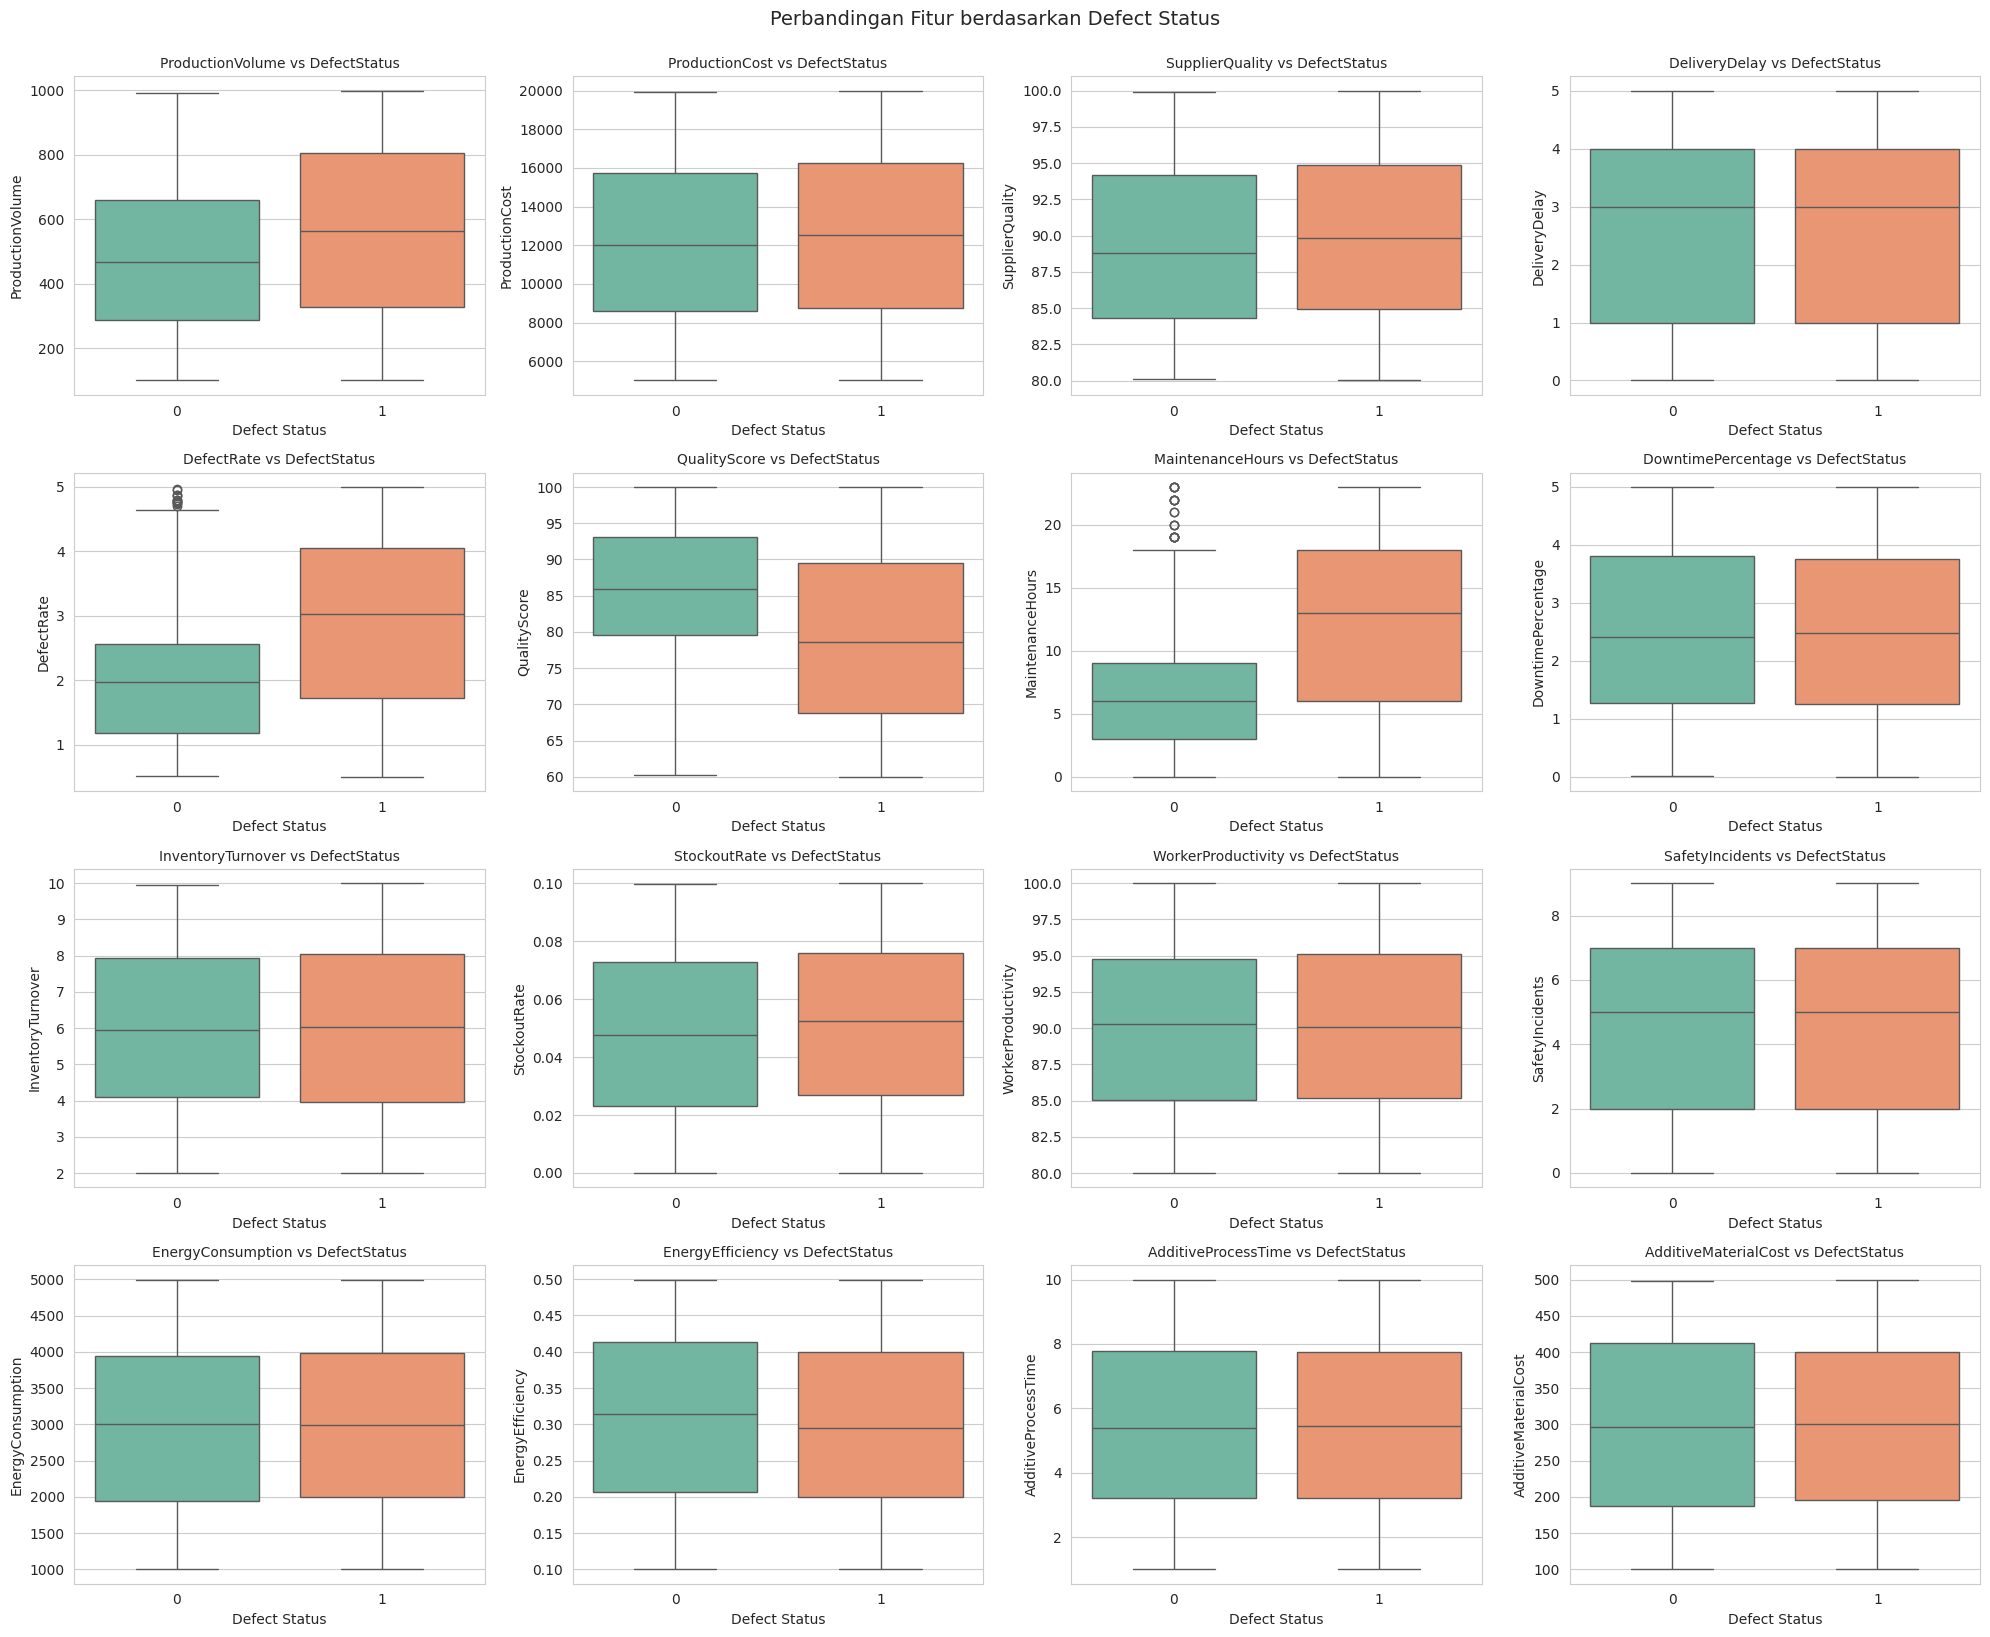

In [12]:
# Boxplot fitur vs target
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(x='DefectStatus', y=col, data=df, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col} vs DefectStatus', fontsize=10)
    axes[i].set_xlabel('Defect Status')

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.suptitle('Perbandingan Fitur berdasarkan Defect Status', fontsize=14, y=1.02)
plt.show()

In [13]:
# Fitur baru: total cost
df['Total_Cost'] = df['ProductionVolume'] * df['ProductionCost']

# Fitur baru: efficiency ratio
df['Efficiency_Ratio'] = df['WorkerProductivity'] / (df['EnergyConsumption'] + 1)

# Fitur baru: quality index
df['Quality_Index'] = df['QualityScore'] / (df['DefectRate'] + 1)

# Fitur baru: maintenance intensity
df['Maintenance_Intensity'] = df['MaintenanceHours'] / (df['DowntimePercentage'] + 1)

print("Fitur baru yang dibuat:")
print(df[['Total_Cost', 'Efficiency_Ratio', 'Quality_Index', 'Maintenance_Intensity']].describe())

Fitur baru yang dibuat:
         Total_Cost  Efficiency_Ratio  Quality_Index  Maintenance_Intensity
count  3.240000e+03       3240.000000    3240.000000            3240.000000
mean   6.847746e+06          0.036326      24.775336               4.129230
std    4.262288e+06          0.017744      11.078886               3.628246
min    5.300488e+05          0.016262      10.283428               0.000000
25%    3.442429e+06          0.022630      16.263507               1.579725
50%    5.930295e+06          0.030356      21.522663               3.298635
75%    9.622630e+06          0.045006      30.520123               5.418093
max    1.969984e+07          0.096917      65.665111              22.351118


In [14]:
# Cek kolom yang tersedia
print("Kolom setelah feature engineering:")
print(df.columns.tolist())

# Hapus kolom jika ada identifier unik (tidak ada dalam dataset ini)
# df_clean = df.drop(['ID'], axis=1)  # Jika ada

df_clean = df.copy()
print(f"\nShape df_clean: {df_clean.shape}")

Kolom setelah feature engineering:
['ProductionVolume', 'ProductionCost', 'SupplierQuality', 'DeliveryDelay', 'DefectRate', 'QualityScore', 'MaintenanceHours', 'DowntimePercentage', 'InventoryTurnover', 'StockoutRate', 'WorkerProductivity', 'SafetyIncidents', 'EnergyConsumption', 'EnergyEfficiency', 'AdditiveProcessTime', 'AdditiveMaterialCost', 'DefectStatus', 'Total_Cost', 'Efficiency_Ratio', 'Quality_Index', 'Maintenance_Intensity']

Shape df_clean: (3240, 21)


In [15]:
# Tentukan fitur dan target
feature_cols = [col for col in df_clean.columns if col != 'DefectStatus']
X = df_clean[feature_cols]
y = df_clean['DefectStatus']

print("Shape X:", X.shape)
print("Shape y:", y.shape)
print(f"\nJumlah fitur: {len(feature_cols)}")
print("\nDistribusi Target:")
print(y.value_counts())

Shape X: (3240, 20)
Shape y: (3240,)

Jumlah fitur: 20

Distribusi Target:
DefectStatus
1    2723
0     517
Name: count, dtype: int64


In [17]:
# Bagi data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])
print("\nDistribusi target di training:")
print(y_train.value_counts(normalize=True))
print("\nDistribusi target di testing:")
print(y_test.value_counts(normalize=True))

Jumlah data training: 2592
Jumlah data testing: 648

Distribusi target di training:
DefectStatus
1    0.840278
0    0.159722
Name: proportion, dtype: float64

Distribusi target di testing:
DefectStatus
1    0.841049
0    0.158951
Name: proportion, dtype: float64


In [18]:
# Standardisasi fitur numerik
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Mean training setelah scaling (harus mendekati 0):")
print(X_train_scaled.mean(axis=0).round(4)[:5], "...")
print("\nStd training setelah scaling (harus mendekati 1):")
print(X_train_scaled.std(axis=0).round(4)[:5], "...")

Mean training setelah scaling (harus mendekati 0):
[ 0. -0. -0. -0.  0.] ...

Std training setelah scaling (harus mendekati 1):
[1. 1. 1. 1. 1.] ...


In [19]:
# Inisialisasi model
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': GaussianNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
}

# Dictionary untuk menyimpan hasil
results = {}

# Latih dan evaluasi setiap model
for name, model in models.items():
    # Latih model
    model.fit(X_train_scaled, y_train)

    # Prediksi
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)
    y_test_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Hitung metrik
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred, zero_division=0)
    recall = recall_score(y_test, y_test_pred, zero_division=0)
    f1 = f1_score(y_test, y_test_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_test_proba)

    # Simpan hasil
    results[name] = {
        'model': model,
        'train_accuracy': train_acc,
        'test_accuracy': test_acc,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'auc_roc': auc,
        'y_test_pred': y_test_pred,
        'y_test_proba': y_test_proba
    }

    print(f"{'='*60}")
    print(f"Model: {name}")
    print(f"Train Accuracy : {train_acc:.4f}")
    print(f"Test Accuracy  : {test_acc:.4f}")
    print(f"Precision      : {precision:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"F1-Score       : {f1:.4f}")
    print(f"AUC-ROC        : {auc:.4f}")
    print()

Model: Decision Tree
Train Accuracy : 0.9684
Test Accuracy  : 0.9383
Precision      : 0.9501
Recall         : 0.9780
F1-Score       : 0.9638
AUC-ROC        : 0.8618

Model: K-Nearest Neighbors
Train Accuracy : 0.9132
Test Accuracy  : 0.8796
Precision      : 0.9005
Recall         : 0.9633
F1-Score       : 0.9309
AUC-ROC        : 0.7484

Model: Naive Bayes
Train Accuracy : 0.8877
Test Accuracy  : 0.8704
Precision      : 0.9229
Recall         : 0.9229
F1-Score       : 0.9229
AUC-ROC        : 0.7973

Model: Logistic Regression
Train Accuracy : 0.8808
Test Accuracy  : 0.8796
Precision      : 0.8938
Recall         : 0.9725
F1-Score       : 0.9315
AUC-ROC        : 0.7991

Model: Random Forest
Train Accuracy : 0.9803
Test Accuracy  : 0.9506
Precision      : 0.9508
Recall         : 0.9927
F1-Score       : 0.9713
AUC-ROC        : 0.8163



In [20]:
# Buat DataFrame perbandingan
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Train Acc': [results[m]['train_accuracy'] for m in results],
    'Test Acc': [results[m]['test_accuracy'] for m in results],
    'Precision': [results[m]['precision'] for m in results],
    'Recall': [results[m]['recall'] for m in results],
    'F1-Score': [results[m]['f1_score'] for m in results],
    'AUC-ROC': [results[m]['auc_roc'] for m in results]
}).round(4)

# Hitung selisih (indikasi overfitting)
comparison_df['Overfit Gap'] = (
    comparison_df['Train Acc'] - comparison_df['Test Acc']
).round(4)

comparison_df = comparison_df.sort_values('F1-Score', ascending=False)
print("Perbandingan Model:")
print(comparison_df.to_string(index=False))

Perbandingan Model:
              Model  Train Acc  Test Acc  Precision  Recall  F1-Score  AUC-ROC  Overfit Gap
      Random Forest     0.9803    0.9506     0.9508  0.9927    0.9713   0.8163       0.0297
      Decision Tree     0.9684    0.9383     0.9501  0.9780    0.9638   0.8618       0.0301
Logistic Regression     0.8808    0.8796     0.8938  0.9725    0.9315   0.7991       0.0012
K-Nearest Neighbors     0.9132    0.8796     0.9005  0.9633    0.9309   0.7484       0.0336
        Naive Bayes     0.8877    0.8704     0.9229  0.9229    0.9229   0.7973       0.0173


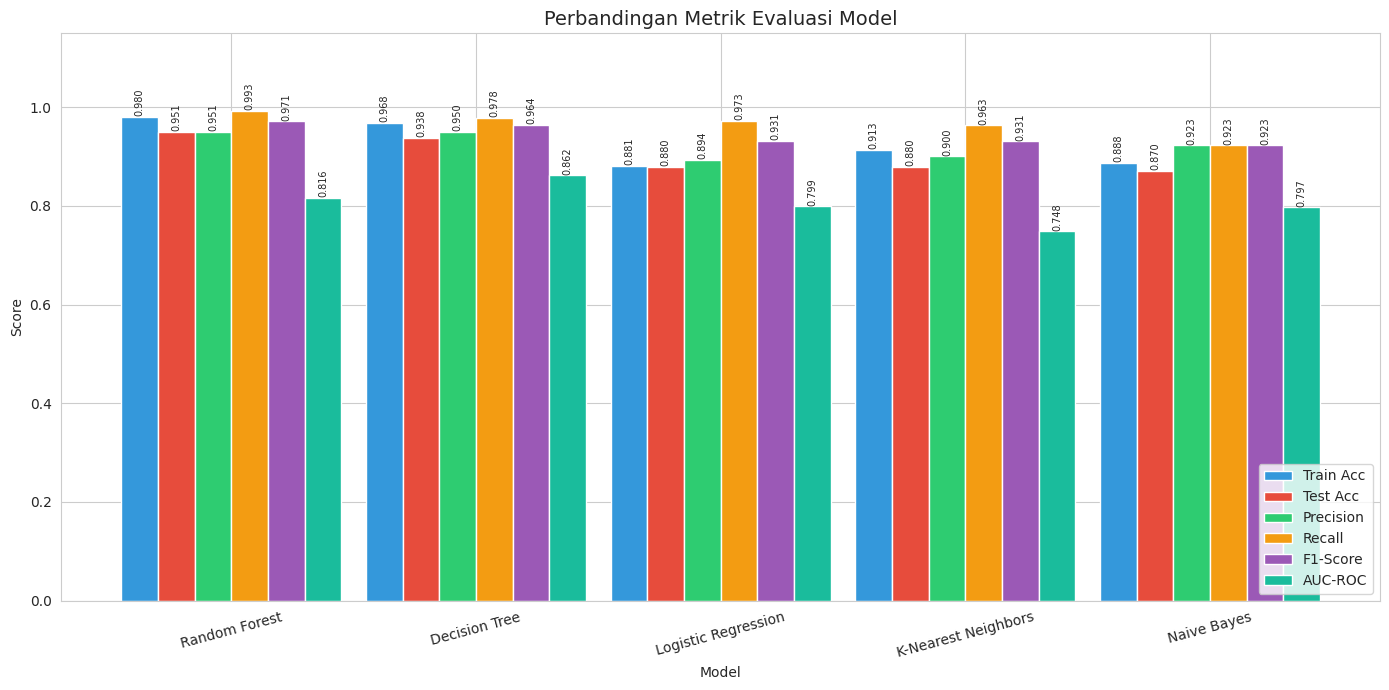

In [21]:
# Bar chart perbandingan
fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(comparison_df))
width = 0.15

metrics = ['Train Acc', 'Test Acc', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c']

for i, (metric, color) in enumerate(zip(metrics, colors)):
    bars = ax.bar(x + i*width - 2.5*width, comparison_df[metric],
                  width, label=metric, color=color)
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 2), textcoords="offset points",
                    ha='center', fontsize=7, rotation=90)

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Perbandingan Metrik Evaluasi Model', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Model'], rotation=15)
ax.legend(loc='lower right')
ax.set_ylim(0, 1.15)
plt.tight_layout()
plt.show()

Model Terbaik: Random Forest



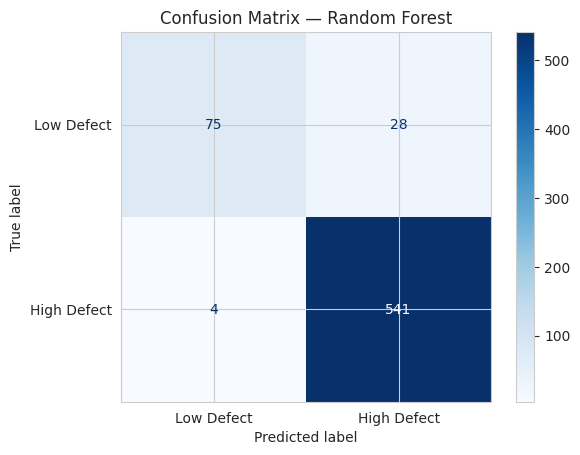

Classification Report — Random Forest:

              precision    recall  f1-score   support

  Low Defect       0.95      0.73      0.82       103
 High Defect       0.95      0.99      0.97       545

    accuracy                           0.95       648
   macro avg       0.95      0.86      0.90       648
weighted avg       0.95      0.95      0.95       648



In [22]:
# Ambil model terbaik berdasarkan F1-Score
best_model_name = comparison_df.iloc[0]['Model']
best_model = results[best_model_name]['model']
best_y_pred = results[best_model_name]['y_test_pred']

print(f"Model Terbaik: {best_model_name}\n")

# Confusion Matrix
cm = confusion_matrix(y_test, best_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['Low Defect', 'High Defect'])
disp.plot(cmap='Blues')
plt.title(f'Confusion Matrix — {best_model_name}')
plt.show()

# Classification Report
print(f"Classification Report — {best_model_name}:\n")
print(classification_report(y_test, best_y_pred,
                            target_names=['Low Defect', 'High Defect']))

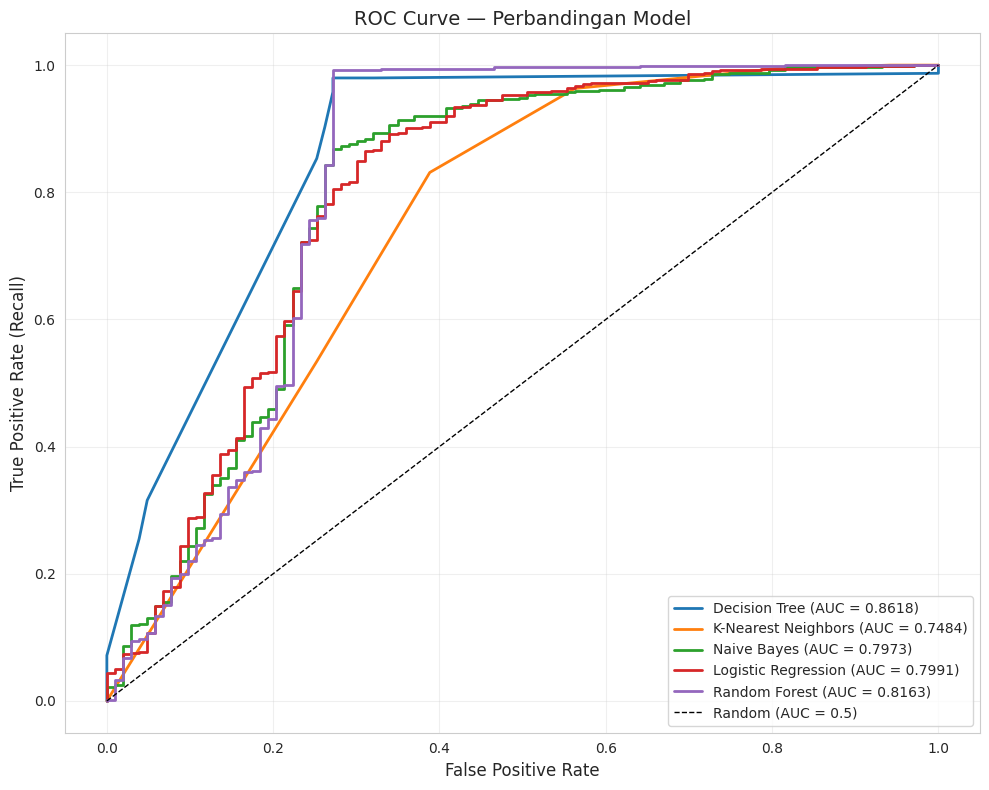

In [23]:
# ROC Curve untuk semua model
plt.figure(figsize=(10, 8))

for name in results:
    y_proba = results[name]['y_test_proba']
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = results[name]['auc_roc']
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC Curve — Perbandingan Model', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Feature Importance (Random Forest):
                Fitur  Importance
     MaintenanceHours    0.160067
         QualityScore    0.140420
           DefectRate    0.135335
        Quality_Index    0.132262
Maintenance_Intensity    0.088749
     ProductionVolume    0.081758
           Total_Cost    0.037871
   DowntimePercentage    0.022236
 AdditiveMaterialCost    0.022230
     EnergyEfficiency    0.021863
         StockoutRate    0.021327
    InventoryTurnover    0.019358
       ProductionCost    0.018247
   WorkerProductivity    0.017638
     Efficiency_Ratio    0.017450
      SupplierQuality    0.017013
    EnergyConsumption    0.016674
  AdditiveProcessTime    0.015728
      SafetyIncidents    0.007962
        DeliveryDelay    0.005812


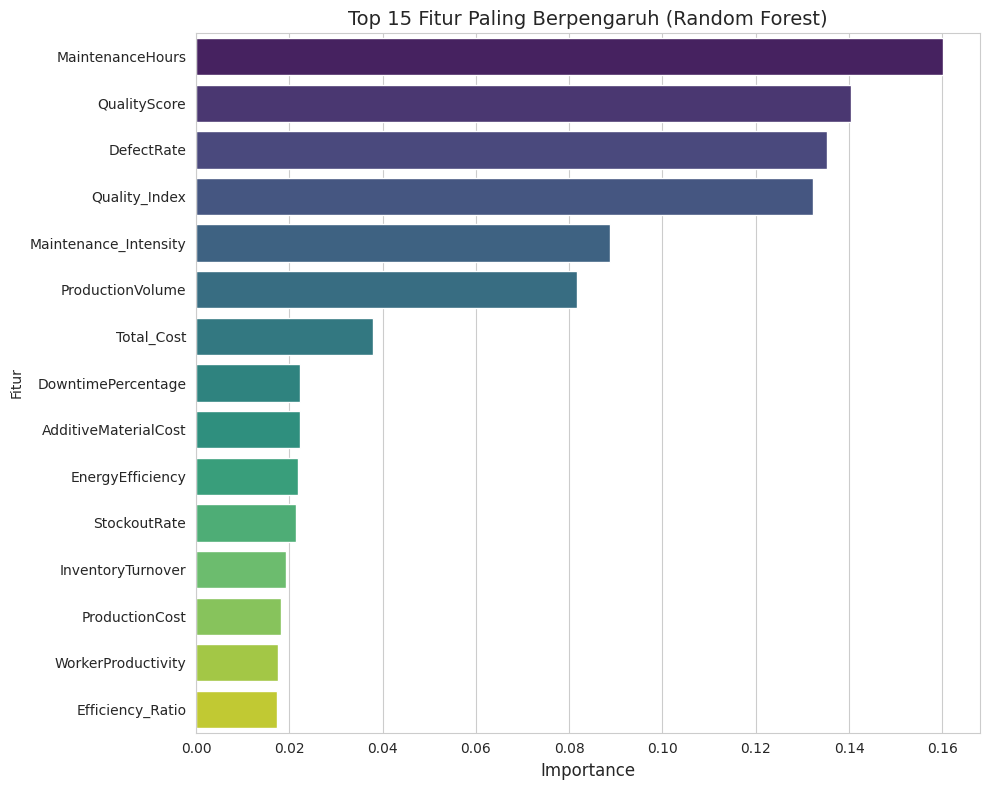

In [24]:
# Feature importance dari Random Forest
rf_model = results['Random Forest']['model']
feature_importance = pd.DataFrame({
    'Fitur': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("Feature Importance (Random Forest):")
print(feature_importance.to_string(index=False))

# Visualisasi
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Fitur', data=feature_importance.head(15),
            palette='viridis')
plt.title('Top 15 Fitur Paling Berpengaruh (Random Forest)', fontsize=14)
plt.xlabel('Importance', fontsize=12)
plt.tight_layout()
plt.show()

In [25]:
# Latih ulang model dengan class_weight='balanced'
models_balanced = {
    'Decision Tree (Balanced)': DecisionTreeClassifier(
        max_depth=5, class_weight='balanced', random_state=42),
    'Logistic Regression (Balanced)': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest (Balanced)': RandomForestClassifier(
        n_estimators=100, max_depth=10, class_weight='balanced', random_state=42)
}

print("Perbandingan dengan Class Weight Balancing:")
print("=" * 80)

for name, model in models_balanced.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba)

    print(f"\n{name}:")
    print(f"  Accuracy: {acc:.4f} | Precision: {prec:.4f} | "
          f"Recall: {rec:.4f} | F1: {f1:.4f} | AUC: {auc:.4f}")

Perbandingan dengan Class Weight Balancing:

Decision Tree (Balanced):
  Accuracy: 0.9074 | Precision: 0.9482 | Recall: 0.9413 | F1: 0.9448 | AUC: 0.8697

Logistic Regression (Balanced):
  Accuracy: 0.7407 | Precision: 0.9394 | Recall: 0.7394 | F1: 0.8275 | AUC: 0.7959

Random Forest (Balanced):
  Accuracy: 0.9506 | Precision: 0.9508 | Recall: 0.9927 | F1: 0.9713 | AUC: 0.8203


In [26]:
# 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("5-Fold Cross-Validation (F1-Score):")
print("=" * 60)

for name, model in models.items():
    scores = cross_val_score(model, X_train_scaled, y_train,
                             cv=cv, scoring='f1')
    print(f"{name}: F1 = {scores.mean():.4f} ± {scores.std():.4f}")

5-Fold Cross-Validation (F1-Score):
Decision Tree: F1 = 0.9698 ± 0.0069
K-Nearest Neighbors: F1 = 0.9246 ± 0.0028
Naive Bayes: F1 = 0.9298 ± 0.0102
Logistic Regression: F1 = 0.9303 ± 0.0057
Random Forest: F1 = 0.9753 ± 0.0046


In [27]:
print("=" * 70)
print("RINGKASAN HASIL PRAKTIKUM — PREDIKSI DEFECT PRODUK MANUFAKTUR")
print("=" * 70)

print(f"""
1. DATASET
   - Sumber: Kaggle — Predicting Manufacturing Defects Dataset
   - Jumlah data: {len(df)} record
   - Jumlah fitur: {len(feature_cols)} fitur
   - Target: DefectStatus (0=Low, 1=High)
   - Class imbalance: {y.value_counts(normalize=True).round(4).to_dict()}

2. PREPROCESSING
   - Missing value: {df.isnull().sum().sum()}
   - Duplikat: {df.duplicated().sum()}
   - Fitur baru dibuat: Total_Cost, Efficiency_Ratio, Quality_Index, Maintenance_Intensity
   - Scaling: StandardScaler
   - Split: 80% train, 20% test (stratified)

3. HASIL PERBANDINGAN MODEL (Test Set)
""")

for _, row in comparison_df.iterrows():
    print(f"   {row['Model']:30s} | F1={row['F1-Score']:.4f} | "
          f"AUC={row['AUC-ROC']:.4f} | Recall={row['Recall']:.4f}")

print(f"""
4. MODEL TERBAIK: {best_model_name}
   - F1-Score: {results[best_model_name]['f1_score']:.4f}
   - AUC-ROC: {results[best_model_name]['auc_roc']:.4f}
   - Recall: {results[best_model_name]['recall']:.4f}

5. FITUR PALING BERPENGARUH (Top 5):
""")

for _, row in feature_importance.head(5).iterrows():
    print(f"   - {row['Fitur']}: {row['Importance']:.4f}")

print(f"""
6. REKOMENDASI
   - Model {best_model_name} direkomendasikan untuk deployment awal.
   - Prioritaskan monitoring pada fitur: {feature_importance.iloc[0]['Fitur']},
     {feature_importance.iloc[1]['Fitur']}, {feature_importance.iloc[2]['Fitur']}.
   - Pertimbangkan SMOTE untuk meningkatkan Recall kelas minoritas.
""")

RINGKASAN HASIL PRAKTIKUM — PREDIKSI DEFECT PRODUK MANUFAKTUR

1. DATASET
   - Sumber: Kaggle — Predicting Manufacturing Defects Dataset
   - Jumlah data: 3240 record
   - Jumlah fitur: 20 fitur
   - Target: DefectStatus (0=Low, 1=High)
   - Class imbalance: {1: 0.8404, 0: 0.1596}

2. PREPROCESSING
   - Missing value: 0
   - Duplikat: 0
   - Fitur baru dibuat: Total_Cost, Efficiency_Ratio, Quality_Index, Maintenance_Intensity
   - Scaling: StandardScaler
   - Split: 80% train, 20% test (stratified)

3. HASIL PERBANDINGAN MODEL (Test Set)

   Random Forest                  | F1=0.9713 | AUC=0.8163 | Recall=0.9927
   Decision Tree                  | F1=0.9638 | AUC=0.8618 | Recall=0.9780
   Logistic Regression            | F1=0.9315 | AUC=0.7991 | Recall=0.9725
   K-Nearest Neighbors            | F1=0.9309 | AUC=0.7484 | Recall=0.9633
   Naive Bayes                    | F1=0.9229 | AUC=0.7973 | Recall=0.9229

4. MODEL TERBAIK: Random Forest
   - F1-Score: 0.9713
   - AUC-ROC: 0.8163
   -

# Tugas Praktikum: Eksperimen Hyperparameter dan Interpretasi

> **Catatan:** Jalankan notebook dari awal sampai akhir dan pastikan file `manufacturing_defect_dataset.csv` tersedia saat diminta diunggah. Tabel dan grafik di bawah dihitung langsung dari data, bukan angka contoh. Kelas positif diasumsikan `DefectStatus = 1` (High Defect).

In [ ]:
# 1. Eksperimen Hyperparameter Decision Tree: max_depth
dt_depths = [3, 5, 7, 10, 15]
dt_results = []

for depth in dt_depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]
    dt_results.append({
        "max_depth": depth,
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, proba),
        "Train F1": f1_score(y_train, model.predict(X_train_scaled), zero_division=0)
    })

dt_results_df = pd.DataFrame(dt_results).round(4)
display(dt_results_df)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(dt_results_df["max_depth"], dt_results_df["F1-Score"], marker="o", label="F1-Score")
ax.plot(dt_results_df["max_depth"], dt_results_df["AUC-ROC"], marker="s", label="AUC-ROC")
ax.set_xlabel("max_depth")
ax.set_ylabel("Skor")
ax.set_title("Eksperimen Decision Tree: max_depth")
ax.set_xticks(dt_depths)
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

best_dt_row = dt_results_df.sort_values(["F1-Score", "AUC-ROC"], ascending=False).iloc[0]
print(f"Pilihan terbaik berdasarkan F1-Score (AUC-ROC sebagai pemecah seri): max_depth={int(best_dt_row['max_depth'])}, "
      f"F1={best_dt_row['F1-Score']:.4f}, AUC-ROC={best_dt_row['AUC-ROC']:.4f}.")
print("Periksa juga selisih Train F1 dan Test F1: selisih besar pada kedalaman tinggi dapat mengindikasikan overfitting.")


### Interpretasi Decision Tree

Gunakan tabel dan grafik hasil eksekusi untuk menentukan kedalaman terbaik. Pilih nilai dengan **F1-Score pengujian tertinggi**; jika nilainya hampir sama, pertimbangkan AUC-ROC dan model yang lebih sederhana. Kedalaman besar tidak otomatis lebih baik: pohon yang terlalu dalam dapat mempelajari noise. Bandingkan `Train F1` dengan `F1-Score` pengujian untuk menilai indikasi overfitting. Kesimpulan akhir harus mengikuti angka hasil eksekusi pada dataset ini.

In [ ]:
# 2. Eksperimen KNN: n_neighbors (K)
k_values = [3, 5, 7, 9, 11]
knn_results = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    knn_results.append({
        "K": k,
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "Train F1": f1_score(y_train, model.predict(X_train_scaled), zero_division=0)
    })

knn_results_df = pd.DataFrame(knn_results).round(4)
display(knn_results_df)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(knn_results_df["K"], knn_results_df["F1-Score"], marker="o", label="F1-Score")
ax.plot(knn_results_df["K"], knn_results_df["Recall"], marker="s", label="Recall")
ax.set_xlabel("Jumlah tetangga (K)")
ax.set_ylabel("Skor")
ax.set_title("Eksperimen KNN: Pengaruh Nilai K")
ax.set_xticks(k_values)
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

best_knn_row = knn_results_df.sort_values(["F1-Score", "Recall"], ascending=False).iloc[0]
print(f"Pilihan terbaik berdasarkan F1-Score (Recall sebagai pemecah seri): K={int(best_knn_row['K'])}, "
      f"F1={best_knn_row['F1-Score']:.4f}, Recall={best_knn_row['Recall']:.4f}.")
print("Untuk quality control, perhatikan Recall juga karena false negative berarti produk defect dapat lolos.")


### Interpretasi KNN

Nilai K terbaik dipilih dari hasil pengujian, dengan F1-Score sebagai ukuran keseimbangan Precision dan Recall. Jika dua nilai K memiliki F1 yang mirip, Recall dapat menjadi pertimbangan tambahan karena produk defect yang tidak terdeteksi (false negative) dapat lolos ke pelanggan. K terlalu kecil cenderung sensitif terhadap noise, sedangkan K terlalu besar dapat menghaluskan pola lokal dan menyebabkan underfitting.

In [ ]:
# 3. Visualisasi tambahan: DefectRate vs DefectStatus
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="DefectStatus", y="DefectRate", ax=axes[0], palette="Set2")
axes[0].set_title("Distribusi DefectRate berdasarkan DefectStatus")
axes[0].set_xlabel("DefectStatus (0=Low, 1=High)")
axes[0].set_ylabel("DefectRate")

sns.scatterplot(data=df, x="ProductionVolume", y="DefectRate",
                hue="DefectStatus", palette="Set1", alpha=0.7, ax=axes[1])
axes[1].set_title("ProductionVolume vs DefectRate")
axes[1].set_xlabel("ProductionVolume")
axes[1].set_ylabel("DefectRate")
axes[1].legend(title="DefectStatus")

plt.tight_layout()
plt.show()

print("Median DefectRate per DefectStatus:")
display(df.groupby("DefectStatus")["DefectRate"].agg(["count", "mean", "median", "std"]).round(4))
print("Interpretasi: bandingkan median, rentang antarkuartil, dan tumpang tindih boxplot. Pada scatter plot, amati apakah kelas memiliki pola/kelompok berbeda atau banyak tumpang tindih. Visualisasi menunjukkan asosiasi, bukan bukti sebab-akibat.")


## 4. Pertanyaan Konsep

### 1. Mengapa accuracy tidak cukup untuk data imbalanced? Berikan contoh.

Accuracy menghitung proporsi seluruh prediksi yang benar, sehingga dapat tampak tinggi ketika model hanya menebak kelas mayoritas. Contoh: dari 1.000 produk, 950 baik dan 50 defect. Model yang selalu memprediksi “baik” memperoleh accuracy 95%, tetapi Recall untuk kelas defect adalah 0% karena tidak satu pun defect terdeteksi. Karena itu, perhatikan Precision, Recall, F1-Score, dan AUC-ROC.

### 2. Apa perbedaan Precision dan Recall? Dalam konteks defect produk, mana yang lebih penting?

**Precision** = TP/(TP+FP), yaitu proporsi prediksi defect yang memang benar-benar defect. **Recall** = TP/(TP+FN), yaitu proporsi seluruh produk defect yang berhasil ditemukan model. Pada manufaktur, Recall sering diprioritaskan karena false negative membuat produk cacat lolos ke pasar dan dapat menimbulkan biaya atau risiko keselamatan. Namun, Precision juga penting agar terlalu banyak produk baik tidak ditahan atau dibuang.

### 3. Mengapa `stratify=y` penting pada `train_test_split`?

`stratify=y` menjaga proporsi kelas target pada data training dan testing agar mendekati distribusi dataset asal. Ini penting ketika kelas tidak seimbang supaya kelas minoritas tidak terlalu sedikit atau tidak terwakili di salah satu bagian, sehingga evaluasi lebih representatif.

### 4. Apa itu overfitting? Bagaimana mendeteksinya dari tabel perbandingan?

Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training, termasuk noise, sehingga performa pada data baru lebih buruk. Indikasinya adalah skor training jauh lebih tinggi daripada skor testing, misalnya Train Accuracy 0,99 tetapi Test Accuracy 0,70. Periksa kolom `Overfit Gap` dan bandingkan metrik training-testing. Selisih besar merupakan indikasi, bukan bukti tunggal; cross-validation dapat membantu konfirmasi.

### 5. Mengapa Random Forest sering lebih baik dari Decision Tree tunggal?

Random Forest menggabungkan banyak pohon yang dilatih pada bootstrap sample dan subset fitur acak. Voting antar-pohon mengurangi varians dan ketergantungan pada satu pohon, sehingga umumnya lebih stabil dan lebih tahan terhadap overfitting. Kekurangannya, interpretasi model gabungan lebih sulit dan kebutuhan komputasinya lebih besar.

## 5. Refleksi Pribadi (contoh, minimal 200 kata)

Melalui praktikum ini saya mempelajari alur dasar penerapan supervised learning untuk memprediksi status defect pada produk manufaktur. Saya memahami bahwa proses machine learning tidak hanya memilih algoritma dan menjalankan kode, tetapi dimulai dari memahami dataset, memeriksa missing value dan duplikasi, mengenali distribusi target, menyiapkan fitur, membagi data, melakukan scaling bila diperlukan, melatih model, lalu mengevaluasi hasilnya. Saya juga belajar bahwa pemilihan metrik harus sesuai dengan masalah yang dihadapi. Pada data defect yang tidak seimbang, accuracy saja dapat menyesatkan karena model bisa terlihat bagus meskipun gagal menemukan produk cacat.

Bagian yang paling sulit bagi saya adalah membandingkan model dan menentukan parameter yang tepat tanpa hanya berpatokan pada satu angka. Perubahan `max_depth` pada Decision Tree dapat mengubah kompleksitas pohon, sedangkan perubahan nilai K pada KNN memengaruhi cara model menentukan kelas berdasarkan tetangga terdekat. Saya perlu membaca F1-Score, Recall, dan AUC-ROC secara bersamaan serta memperhatikan kemungkinan overfitting dari perbedaan skor training dan testing. Visualisasi seperti boxplot dan scatter plot juga perlu ditafsirkan secara hati-hati karena pola atau korelasi yang terlihat tidak otomatis membuktikan hubungan sebab-akibat.

Di industri manufaktur, saya akan menerapkan machine learning sebagai sistem pendukung keputusan untuk membantu inspeksi kualitas dan mendeteksi risiko defect lebih awal. Data yang dapat digunakan antara lain suhu dan tekanan proses, kecepatan mesin, volume produksi, jam maintenance, konsumsi energi, serta hasil inspeksi kualitas. Model dapat memberi peringatan kepada operator ketika risiko defect meningkat sehingga pemeriksaan atau perawatan dapat dilakukan lebih cepat. Sebelum diterapkan, model harus diuji pada data yang representatif, dipantau secara berkala, dan dievaluasi kembali saat kondisi produksi berubah. Keputusan akhir tetap melibatkan operator dan tim quality control agar hasil prediksi dapat diperiksa berdasarkan pengetahuan proses, standar kualitas, dan keselamatan kerja.

> **Catatan personalisasi:** Sesuaikan refleksi ini dengan pengalaman Anda sendiri, terutama bagian yang paling sulit dan rencana penerapan yang benar-benar ingin Anda lakukan.

---
**Sebelum mengumpulkan:** jalankan semua cell dari atas ke bawah, pastikan seluruh tabel/grafik muncul, lalu simpan notebook dengan output. Angka hasil eksperimen harus berasal dari eksekusi dataset yang digunakan, bukan ditebak atau diisi manual.